In [1]:
import sys
sys.path.append("../src")

import cv2
import numpy as np
%pip install pandas
import pandas as pd
import matplotlib.pyplot as plt

from utils_cv import baca, tampil, kontras_bercak


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: C:\Users\mucha\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


KB kanal B   : 1.68
KB kanal G   : 2.48
KB kanal R   : 13.88
KB kanal Gray: 6.82
KB kanal H   : 10.72
KB kanal S   : 0.82
KB kanal V   : 4.40


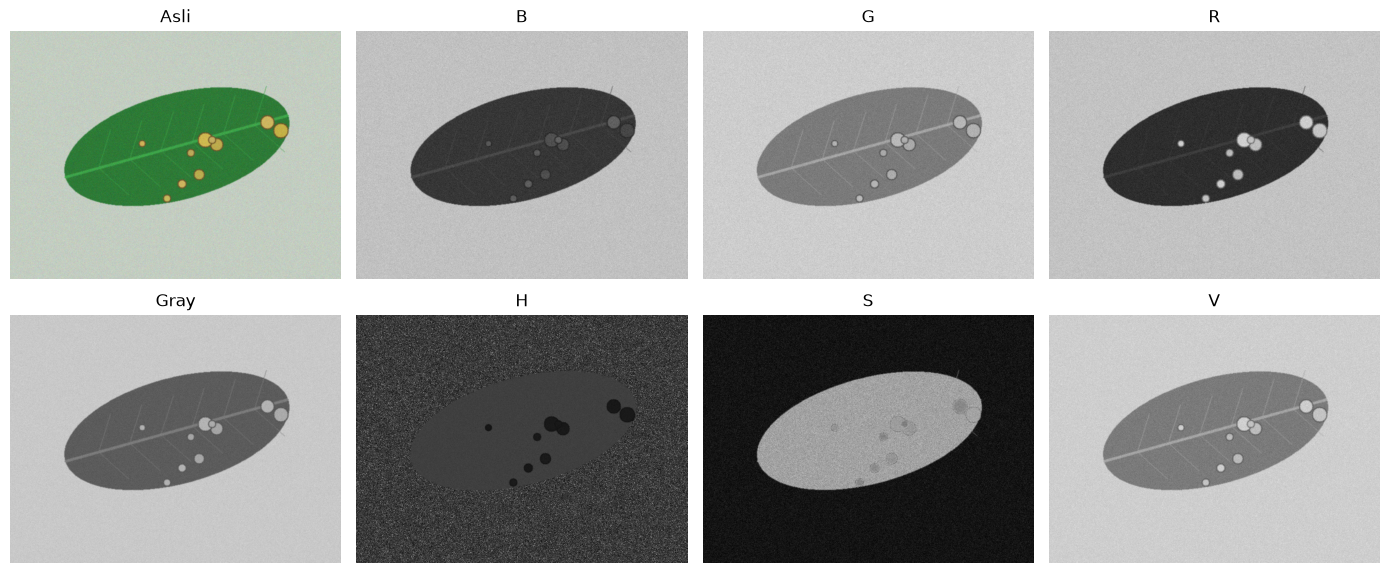

In [2]:
nama = "teh_041.png"

img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)

kanal = {
    "B": b,
    "G": g,
    "R": r,
    "Gray": gray,
    "H": h,
    "S": s,
    "V": v
}

tampil(
    [img] + list(kanal.values()),
    ["Asli"] + list(kanal.keys()),
    baris=2,
    ukuran=(14, 6)
)

for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

In [3]:
# Sampling: perkecil lalu perbesar kembali ke ukuran semula
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(
        gray,
        None,
        fx=fx,
        fy=fx,
        interpolation=cv2.INTER_AREA
    )

    besar = cv2.resize(
        kecil,
        gray.shape[::-1],
        interpolation=cv2.INTER_NEAREST
    )

    print(
        f"fx={fx}: ukuran {kecil.shape}, "
        f"KB={kontras_bercak(besar, md, mb):.2f}"
    )

# Kuantisasi: sisakan k bit
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah

    print(
        f"k={k}: {len(np.unique(kuant))} level, "
        f"KB={kontras_bercak(kuant, md, mb):.2f}"
    )

fx=0.5: ukuran (240, 320), KB=6.99
fx=0.2: ukuran (96, 128), KB=5.55
fx=0.1: ukuran (48, 64), KB=3.67
fx=0.05: ukuran (24, 32), KB=1.56
k=1: 2 level, KB=8.08
k=2: 3 level, KB=8.09
k=3: 5 level, KB=3.91
k=4: 10 level, KB=5.87
k=8: 151 level, KB=6.82


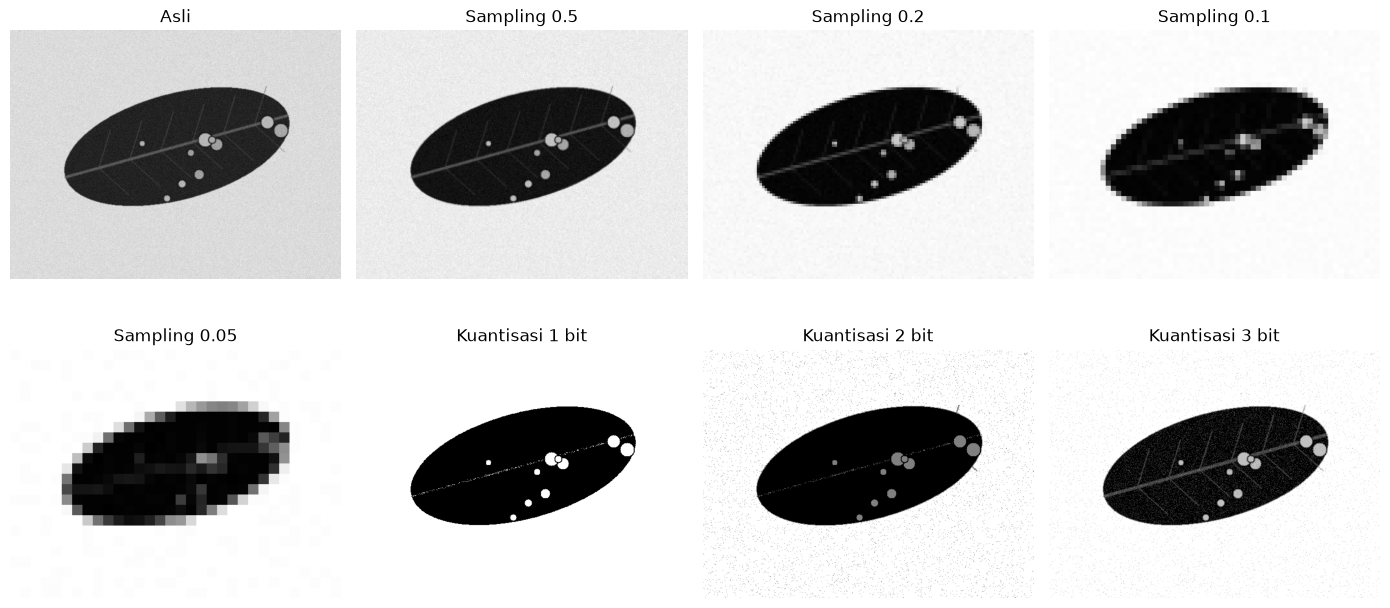

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

axes = axes.flatten()

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Asli")

for i, fx in enumerate([0.5, 0.2, 0.1, 0.05], start=1):
    kecil = cv2.resize(
        gray, None,
        fx=fx, fy=fx,
        interpolation=cv2.INTER_AREA
    )

    besar = cv2.resize(
        kecil,
        gray.shape[::-1],
        interpolation=cv2.INTER_NEAREST
    )

    axes[i].imshow(besar, cmap="gray")
    axes[i].set_title(f"Sampling {fx}")

for i, k in enumerate([1, 2, 3], start=5):
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah

    axes[i].imshow(kuant, cmap="gray")
    axes[i].set_title(f"Kuantisasi {k} bit")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig("../hasil/b2_sampling_kuantisasi.png", dpi=150)
plt.show()

In [5]:
def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)

    return {
        "B": b,
        "G": g,
        "R": r,
        "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
        "H": h,
        "S": s,
        "V": v
    }


label = pd.read_csv("../data/sintetis/label.csv")

baris = []

for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")

    m_d = cv2.imread(
        f"../data/sintetis/mask_daun/{d.nama_file}", 0
    )

    m_b = cv2.imread(
        f"../data/sintetis/mask_bercak/{d.nama_file}", 0
    )

    kb = {
        k: kontras_bercak(c, m_d, m_b)
        for k, c in semua_kanal(im).items()
    }

    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)

tabel_kb = (
    pd.DataFrame(baris)
    .groupby("kondisi")
    .mean()
    .round(2)
)

print(tabel_kb)

tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")

                   B     G      R  Gray     H     S     V
kondisi                                                  
bayangan        1.33  0.29   5.29  1.59  5.08  0.80  0.99
gelap           0.97  0.85   9.01  3.69  5.25  0.87  2.46
kontras_rendah  0.78  0.46   3.26  1.94  1.30  0.22  1.38
normal          2.34  2.08  10.41  5.72  7.29  1.05  3.70
terang          1.34  0.67   6.06  3.12  4.58  0.67  1.54


In [6]:
baris_ringan = []

for _, d in label[label.kelas == "ringan"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")

    m_d = cv2.imread(
        f"../data/sintetis/mask_daun/{d.nama_file}", 0
    )

    m_b = cv2.imread(
        f"../data/sintetis/mask_bercak/{d.nama_file}", 0
    )

    kb = {
        k: kontras_bercak(c, m_d, m_b)
        for k, c in semua_kanal(im).items()
    }

    kb["kondisi"] = d.kondisi_cahaya
    baris_ringan.append(kb)

tabel_ringan = (
    pd.DataFrame(baris_ringan)
    .groupby("kondisi")
    .mean()
    .round(2)
)

print(tabel_ringan)

tabel_ringan.to_csv("../hasil/b2_kb_ringan.csv")

                   B     G     R  Gray     H     S     V
kondisi                                                 
bayangan        0.66  0.58  4.36  0.72  5.08  0.98  0.43
gelap           1.10  1.17  8.11  2.41  6.53  1.26  1.23
kontras_rendah  0.43  0.23  2.89  1.13  1.48  0.40  0.58
normal          0.95  0.45  8.51  3.25  7.63  0.42  1.76
terang          1.30  0.29  5.09  2.30  4.20  0.92  0.86


teh_021.png: kanal terbaik = R
{'B': np.float64(1.229008864877633), 'G': np.float64(0.15190636803994503), 'R': np.float64(9.03330287644774), 'Gray': np.float64(3.421474483538861), 'H': np.float64(7.73245296650115), 'S': np.float64(0.3107333939098007), 'V': np.float64(2.1460371262329105)}


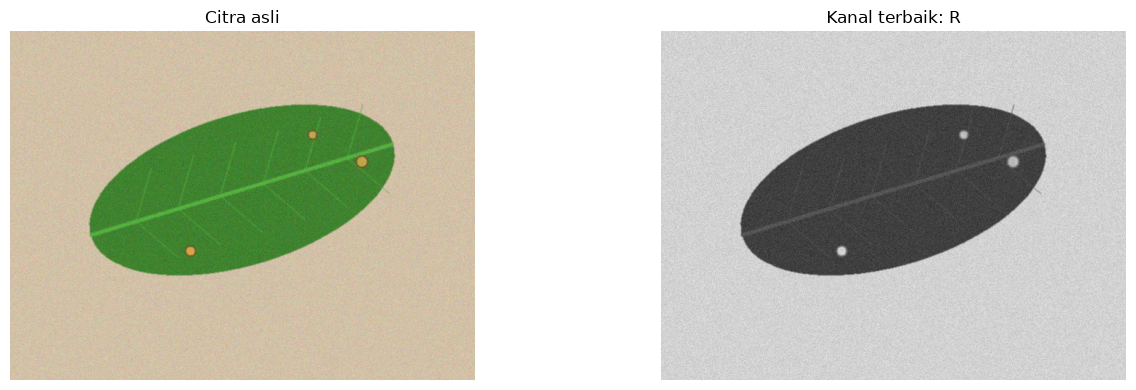

teh_045.png: kanal terbaik = H
{'B': np.float64(2.285109063247173), 'G': np.float64(0.15838570703442603), 'R': np.float64(5.6888047429386726), 'Gray': np.float64(1.6122782369262803), 'H': np.float64(6.182551105479588), 'S': np.float64(1.7100871844431869), 'V': np.float64(0.8393883427210118)}


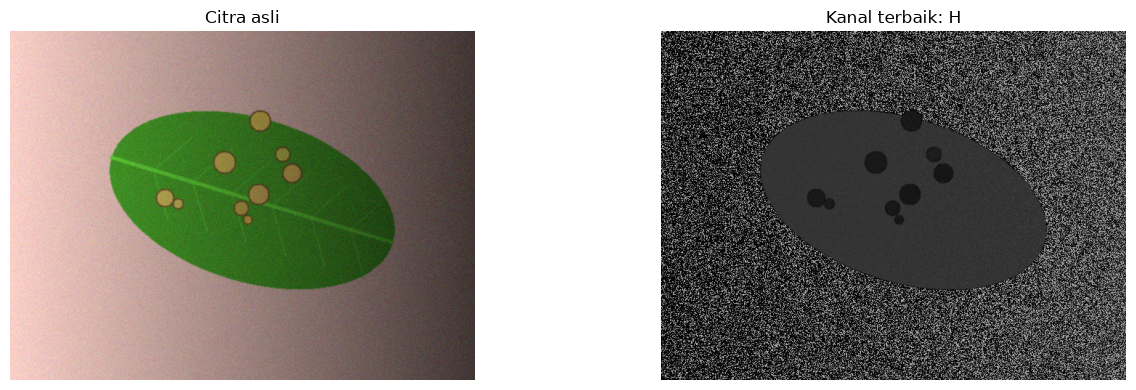

In [7]:
for nama in ["teh_021.png", "teh_045.png"]:
    im = baca(f"../data/sintetis/citra/{nama}")

    kanal_img = semua_kanal(im)

    nilai_kb = {}

    if nama == "teh_021.png":
        md_img = cv2.imread(
            f"../data/sintetis/mask_daun/{nama}", 0
        )
        mb_img = cv2.imread(
            f"../data/sintetis/mask_bercak/{nama}", 0
        )
    else:
        md_img = cv2.imread(
            f"../data/sintetis/mask_daun/{nama}", 0
        )
        mb_img = cv2.imread(
            f"../data/sintetis/mask_bercak/{nama}", 0
        )

    for k, c in kanal_img.items():
        nilai_kb[k] = kontras_bercak(c, md_img, mb_img)

    terbaik = max(nilai_kb, key=nilai_kb.get)

    print(f"{nama}: kanal terbaik = {terbaik}")
    print(nilai_kb)

    tampil(
        [im, kanal_img[terbaik]],
        ["Citra asli", f"Kanal terbaik: {terbaik}"],
        baris=1
    )

    plt.show()